<a href="https://colab.research.google.com/github/Singleeee/T3-IA-Redes-Neurais/blob/main/Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto 3 — Redes Neurais: classificação de subgêneros de ficção científica

**Dataset:** [Science Fiction Books (10,000+)](https://www.kaggle.com/datasets/tanguypledel/science-fiction-books-subgenres) — descrição textual + gêneros de ~10 mil livros.
**Tarefa:** a partir da descrição do livro, prever o subgênero (problema **multiclasse desbalanceado**).

| # | Etapa | Requisito atendido |
|---|-------|--------------------|
| 1 | Carregamento e pré-processamento | seleção de classes, limpeza, TF-IDF |
| 2 | MLP manual (NumPy) | 2 camadas ocultas, forward, backprop, Adam, L2 |
| 3 | MLP em Keras/TensorFlow | modelo equivalente para validar a rede manual |
| 4 | Hiperparâmetros + 5-fold CV | ReLU×Sigmoide, L2×sem L2, nº de neurônios, média e IC 95% |
| 5 | Diagnósticos, métricas, pesos | curvas de aprendizado, heatmaps, saturação, AUROC/P/R/F1, baseline |
| 6 | Embeddings Skip-Gram | substitui TF-IDF, 1 camada oculta |
| 7 | Resumo e conclusão | tabelas e gráficos consolidados |

**Como executar:** Kaggle/Colab (internet ligada: baixa o dataset via `kagglehub`) ou local (coloque o CSV em `./data/` ou defina `SF_CSV=/caminho/arquivo.csv`).
Todas as figuras e tabelas são salvas em `./outputs/`. Para um teste rápido do notebook inteiro use `NB_FAST=1`.

## 1. Carregamento e pré-processamento
### 1.1 Imports e configuração

In [ ]:
# Install dependencies as needed:
# !pip install kagglehub pandas
import kagglehub
import pandas as pd
from pathlib import Path

# Baixa o dataset do Kaggle (retorna o caminho da pasta onde foi salvo)
print("Baixando o dataset...")
dataset_dir = kagglehub.dataset_download("tanguypledel/science-fiction-books-subgenres")
print("Dataset salvo em:", dataset_dir)

# Encontra o arquivo CSV na pasta do dataset
csv_files = list(Path(dataset_dir).rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError("Nenhum arquivo CSV encontrado no dataset baixado.")

file_path = csv_files[0]
print(f"Carregando o arquivo: {file_path.name}")

# Carrega o DataFrame usando o pandas diretamente
df = pd.read_csv(file_path)

print("Primeiros 5 registros:")
display(df.head())

Baixando o dataset...
Using Colab cache for faster access to the 'science-fiction-books-subgenres' dataset.
Dataset salvo em: /kaggle/input/science-fiction-books-subgenres
Carregando o arquivo: sf_cyberpunk.csv
Primeiros 5 registros:


,Book_Title,Original_Book_Title,Author_Name,Edition_Language,Rating_score,Rating_votes,Review_number,Book_Description,Year_published,Genres,url
0,Neuromancer,Neuromancer,William Gibson,English,3.90,268536,9800,Hotwired to the leading edges of art and techn...,1984,"{'Science Fiction': 6796, 'Fiction': 3550, 'Sc...",https://www.goodreads.com/book/show/6088007-ne...
1,Snow Crash,Snow Crash,Neal Stephenson,English,4.02,241095,9391,"In reality, Hiro Protagonist delivers pizza fo...",1992,"{'Science Fiction': 5069, 'Fiction': 3067, 'Sc...",https://www.goodreads.com/book/show/40651883-s...
2,Count Zero,Count Zero,William Gibson,English,4.01,46114,1219,A corporate mercenary wakes in a reconstructed...,1986,"{'Science Fiction': 1480, 'Science Fiction (Cy...",https://www.goodreads.com/book/show/22200.Coun...
3,Altered Carbon,Altered Carbon,Richard K. Morgan,English,4.05,90069,5990,Four hundred years from now mankind is strung ...,2002,"{'Science Fiction': 3185, 'Fiction': 1087, 'Sc...",https://www.goodreads.com/book/show/40792913-a...
4,Mona Lisa Overdrive,Mona Lisa Overdrive,William Gibson,English,3.99,37399,957,"William Gibson, author of the extraordinary mu...",1988,"{'Science Fiction': 1337, 'Science Fiction (Cy...",https://www.goodreads.com/book/show/154091.Mon...


In [ ]:
# Instala a dependência ausente 'gensim'
!pip install -q gensim

In [ ]:
import os, re, ast, time, itertools, warnings
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.dummy import DummyClassifier

import tensorflow as tf
from tensorflow import keras
from gensim.models import Word2Vec

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})

FAST = os.environ.get("NB_FAST", "0") == "1"      # modo de depuração (poucas épocas)
OUT = Path("outputs"); (OUT / "figs").mkdir(parents=True, exist_ok=True)

CFG = dict(
    N_CLASSES    = 6,                 # nº de subgêneros (os mais frequentes), ignorado se SUBGENRES for dado
    SUBGENRES    = None,              # ex.: ["space opera", "dystopia", "time travel"]
    GENERIC      = {"science fiction", "fiction", "sci-fi", "sci fi", "scifi", "sf", "science fiction fantasy"},
    DESC_COL     = None,              # None = detecta automaticamente (coluna com "desc" no nome)
    GENRE_COL    = None,              # None = detecta automaticamente (coluna com "genre" no nome)
    MIN_TOKENS   = 10,                # descarta descrições muito curtas
    MAX_FEATURES = 500 if FAST else 3000,
    EPOCHS       = 4 if FAST else 30,
    BATCH        = 128,
    LR           = 1e-3,
    L2           = 1e-4,              # λ em  CE + λ·ΣW²
    HIDDEN       = (128, 64),         # arquitetura de referência (2 camadas ocultas)
    CLASS_WEIGHT = False,             # True = pondera a perda pelo inverso da frequência da classe
    EMB_DIM      = 10 if FAST else 50,
    EMB_MAXLEN   = 10 if FAST else 40,
    W2V_EPOCHS   = 3 if FAST else 20,
)
TEST_RESULTS = []                      # acumula métricas de teste de todos os modelos (usado na etapa 7)
print("FAST =", FAST, "| TF:", tf.__version__)

FAST = False | TF: 2.21.0


### 1.2 Leitura do CSV e construção do problema multiclasse

In [ ]:
def locate_csv():
    """Procura o CSV: variável SF_CSV -> pastas locais/Kaggle/Colab -> kagglehub."""
    env = os.environ.get("SF_CSV")
    if env and Path(env).exists():
        return [Path(env)]
    cands = []
    for root in [".", "data", "/kaggle/input", "/content", "/mnt/user-data/uploads"]:
        p = Path(root)
        if p.exists():
            cands += [c for c in p.rglob("*.csv") if "outputs" not in c.parts]
    if not cands:
        try:
            import kagglehub
            d = kagglehub.dataset_download("tanguypledel/science-fiction-books-subgenres")
            cands = list(Path(d).rglob("*.csv"))
        except Exception as e:
            print("kagglehub indisponível:", e)
    return sorted(cands, key=lambda c: -c.stat().st_size)

def read_any(path):
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(path, encoding="utf-8", encoding_errors="ignore")

df_raw = None
for c in locate_csv():
    tmp = read_any(c)
    if any("desc" in col.lower() for col in tmp.columns):
        df_raw, CSV_PATH = tmp, c
        break
if df_raw is None:
    raise FileNotFoundError("CSV não encontrado. Baixe o dataset do Kaggle, coloque o .csv em ./data/ "
                            "ou defina a variável de ambiente SF_CSV.")
print("Arquivo:", CSV_PATH, "| formato:", df_raw.shape)
print("Colunas:", list(df_raw.columns))

DESC_COL  = CFG["DESC_COL"]  or next(c for c in df_raw.columns if "desc" in c.lower())
GENRE_COL = CFG["GENRE_COL"] or next((c for c in df_raw.columns if "genre" in c.lower()), None)
print("Coluna de texto:", DESC_COL, "| coluna de gênero:", GENRE_COL)
df_raw.head(3)

Arquivo: /kaggle/input/science-fiction-books-subgenres/sf_alternate_history.csv | formato: (1249, 11)
Colunas: ['Book_Title', 'Original_Book_Title', 'Author_Name', 'Edition_Language', 'Rating_score', 'Rating_votes', 'Review_number', 'Book_Description', 'Year_published', 'Genres', 'url']
Coluna de texto: Book_Description | coluna de gênero: Genres


,Book_Title,Original_Book_Title,Author_Name,Edition_Language,Rating_score,Rating_votes,Review_number,Book_Description,Year_published,Genres,url
0,The Man in the High Castle,The Man in the High Castle,Philip K. Dick,English,3.62,180593,11895,It's America in 1962. Slavery is legal once ag...,1962,"{'Science Fiction': 4175, 'Fiction': 3446, 'Sc...",https://www.goodreads.com/book/show/216363.The...
1,His Majesty's Dragon,His Majesty's Dragon,Naomi Novik,English,4.03,83308,6588,Aerial combat brings a thrilling new dimension...,2006,"{'Fantasy': 7710, 'Fantasy (Dragons) ': 1350, ...",https://www.goodreads.com/book/show/28876.His_...
2,Leviathan,Leviathan,Scott Westerfeld,English,3.90,88293,7052,"Prince Aleksander, would-be heir to the Austro...",2009,"{'Science Fiction (Steampunk) ': 3334, 'Young ...",https://www.goodreads.com/book/show/6050678-le...


In [ ]:
def parse_genres(x):
    """Converte a célula de gêneros em lista de rótulos minúsculos (aceita lista em string, 'a, b', 'a|b')."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return []
    if isinstance(x, (list, tuple, set)):
        items = list(x)
    else:
        s = str(x).strip()
        if s.startswith("[") and s.endswith("]"):
            try:
                items = list(ast.literal_eval(s))
            except Exception:
                items = re.split(r"[,;|]", s.strip("[]"))
        else:
            items = re.split(r"[,;|]", s)
    return [str(i).strip().strip("'\"").lower() for i in items if str(i).strip()]

if GENRE_COL is not None:
    label_lists = df_raw[GENRE_COL].map(parse_genres)
else:  # alternativa: colunas binárias (one-hot) de subgêneros
    onehot = [c for c in df_raw.columns if c != DESC_COL and set(df_raw[c].dropna().unique()) <= {0, 1}]
    print("Sem coluna de gênero; usando colunas one-hot:", onehot)
    label_lists = df_raw[onehot].apply(lambda r: [c.lower() for c in onehot if r[c] == 1], axis=1)

cnt = Counter(g for gs in label_lists for g in set(gs) if g not in CFG["GENERIC"])
print("Subgêneros mais frequentes (sem rótulos genéricos):")
print(pd.Series(cnt).sort_values(ascending=False).head(15).to_string())

Subgêneros mais frequentes (sem rótulos genéricos):
science fiction (alternate history) ': 9     45
science fiction fantasy': 3                  43
science fiction fantasy': 4                  40
science fiction fantasy': 2}                 35
science fiction (alternate history) ': 12    32
science fiction (alternate history) ': 10    32
science fiction (alternate history) ': 13    31
historical (historical fiction) ': 5         31
science fiction fantasy': 2                  28
speculative fiction': 3                      27
war (military fiction) ': 3                  26
fiction': 8                                  25
historical (historical fiction) ': 6         25
fiction': 12                                 24
science fiction fantasy': 5                  24


Aviso: poucos livros com rótulo único; usando a estratégia 'rarest'.
Livros mantidos: 206 de 1249

6 classes | razão de desbalanceamento (maior/menor) = 1.4x


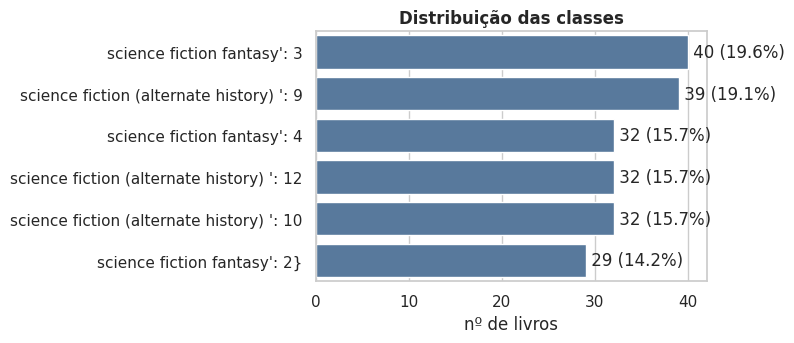

Exemplo limpo: american empire book twoin spectacular thought provoking epic alternate history harry turtledove created unparalleled vision social upheaval war cutthroat politics world like dramatic differences time ...


In [ ]:
chosen = [s.lower() for s in CFG["SUBGENRES"]] if CFG["SUBGENRES"] else [g for g, _ in cnt.most_common(CFG["N_CLASSES"])]
chosen_set = set(chosen)

def assign(gs, strategy):
    inter = [g for g in set(gs) if g in chosen_set]
    if strategy == "unique":                       # exatamente 1 subgênero selecionado
        return inter[0] if len(inter) == 1 else None
    return min(inter, key=lambda g: cnt[g]) if inter else None   # "rarest": o mais raro dentre os selecionados

lab = label_lists.map(lambda gs: assign(gs, "unique"))
if lab.notna().sum() < 1500:                       # poucos exemplos -> usa estratégia alternativa
    print("Aviso: poucos livros com rótulo único; usando a estratégia 'rarest'.")
    lab = label_lists.map(lambda gs: assign(gs, "rarest"))

df = pd.DataFrame({"raw": df_raw[DESC_COL].astype(str), "label_name": lab}).dropna()
print(f"Livros mantidos: {len(df)} de {len(df_raw)}")

# --- limpeza do texto ---
RE_HTML, RE_URL, RE_NON = re.compile(r"<[^>]+>"), re.compile(r"https?://\S+|www\.\S+"), re.compile(r"[^a-z\s]")
STOP = set(ENGLISH_STOP_WORDS)

def clean_text(s):
    s = RE_URL.sub(" ", RE_HTML.sub(" ", str(s).lower())).replace("'", "")
    return " ".join(t for t in RE_NON.sub(" ", s).split() if len(t) > 2 and t not in STOP)

df["text"] = df["raw"].map(clean_text)
df = df[df["text"].str.split().str.len() >= CFG["MIN_TOKENS"]].drop_duplicates("text").reset_index(drop=True)

order = df["label_name"].value_counts().index.tolist()          # classe 0 = mais frequente
classes = order
class2id = {c: i for i, c in enumerate(classes)}
K = len(classes)
y = df["label_name"].map(class2id).to_numpy()
texts = df["text"].to_numpy()
tokens = [t.split() for t in texts]

dist = df["label_name"].value_counts()
print(f"\n{K} classes | razão de desbalanceamento (maior/menor) = {dist.max()/dist.min():.1f}x")
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.barplot(x=dist.values, y=dist.index, ax=ax, color="#4C78A8")
for i, v in enumerate(dist.values):
    ax.text(v, i, f" {v} ({v/len(df):.1%})", va="center")
ax.set_title("Distribuição das classes"); ax.set_xlabel("nº de livros"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(OUT/"figs"/"01_distribuicao_classes.png", dpi=150); plt.show()
print("Exemplo limpo:", texts[0][:200], "...")

### 1.3 Partições e TF-IDF

Para evitar vazamento de dados, usamos três níveis:

* **teste (20%)** — tocado apenas nas métricas finais;
* **treino+validação (`tv`, 80%)** — usado na validação cruzada de 5 folds (etapa 4);
* dentro de `tv`, uma partição **treino/val (80/20)** para as curvas de aprendizado e comparações rápidas (etapas 2, 3 e 5).

O TF-IDF é **sempre ajustado apenas no conjunto de treino** de cada partição/fold.

In [ ]:
idx_all = np.arange(len(df))
idx_tv, idx_test = train_test_split(idx_all, test_size=0.2, stratify=y, random_state=SEED)
idx_tr, idx_val  = train_test_split(idx_tv,  test_size=0.2, stratify=y[idx_tv], random_state=SEED)
print(f"treino={len(idx_tr)} | validação={len(idx_val)} | teste={len(idx_test)}")

def tfidf_features(train_texts, *others):
    vec = TfidfVectorizer(max_features=CFG["MAX_FEATURES"], ngram_range=(1, 2), min_df=3 if not FAST else 2,
                          sublinear_tf=True, dtype=np.float32)
    Xtr = vec.fit_transform(train_texts)
    return (Xtr, *[vec.transform(o) for o in others], vec)

Xtr_t, Xval_t, vec_tr = tfidf_features(texts[idx_tr], texts[idx_val])
print("TF-IDF treino:", Xtr_t.shape, "| esparsidade: %.1f%%" % (100 * (1 - Xtr_t.nnz / np.prod(Xtr_t.shape))))

if CFG["CLASS_WEIGHT"]:
    cnts = np.bincount(y[idx_tv], minlength=K)
    CW = {k: len(idx_tv) / (K * cnts[k]) for k in range(K)}
else:
    CW = None
print("class_weight:", CW)

def compute_metrics(y_true, proba):
    """Métricas multiclasse. AUROC = média macro one-vs-rest. (Em multiclasse de rótulo único, micro-F1 = acurácia.)"""
    proba = np.asarray(proba, dtype=np.float64); proba = proba / proba.sum(1, keepdims=True)
    yp = proba.argmax(1)
    return dict(accuracy=accuracy_score(y_true, yp),
                precision_macro=precision_score(y_true, yp, average="macro", zero_division=0),
                recall_macro=recall_score(y_true, yp, average="macro", zero_division=0),
                f1_micro=f1_score(y_true, yp, average="micro"),
                f1_macro=f1_score(y_true, yp, average="macro", zero_division=0),
                auroc_macro=roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=np.arange(K)))

def mean_ci(x, conf=0.95):
    x = np.asarray(x, float); n = len(x)
    m = x.mean(); h = stats.t.ppf((1 + conf) / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return m, m - h, m + h

treino=130 | validação=33 | teste=41
TF-IDF treino: (130, 923) | esparsidade: 95.6%
class_weight: None


## 2. MLP manual (NumPy)

Arquitetura: `entrada → Dense(h1) → ativação → Dense(h2) → ativação → Dense(K) → softmax`.

**Forward** (camada $l$): $z^{(l)} = a^{(l-1)}W^{(l)} + b^{(l)}$, $\;a^{(l)} = f(z^{(l)})$, $\;\hat y = \mathrm{softmax}(z^{(L)})$.

**Perda:** entropia cruzada + L2: $\;J = \frac1m\sum_i w_i\,(-\log \hat y_{i,y_i}) + \lambda\sum_l\lVert W^{(l)}\rVert^2$.

**Backpropagation** (regra da cadeia, por mini-lote de tamanho $m$):

$$\delta^{(L)} = \frac{\hat Y - Y}{m}, \qquad
\frac{\partial J}{\partial W^{(l)}} = (a^{(l-1)})^\top\delta^{(l)} + 2\lambda W^{(l)}, \qquad
\frac{\partial J}{\partial b^{(l)}} = \sum_i \delta^{(l)}_i, \qquad
\delta^{(l-1)} = \big(\delta^{(l)}(W^{(l)})^\top\big)\odot f'(z^{(l-1)})$$

com $f'(z)=\mathbb 1[z>0]$ (ReLU) ou $f'(z)=a(1-a)$ (sigmoide). A atualização usa **Adam** implementado à mão.
A classe também registra, por época, o que precisamos nas etapas 5: variação dos pesos, norma dos gradientes e saturação.

In [ ]:
def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def to_dense(X, dtype):
    return (X.toarray() if sparse.issparse(X) else np.asarray(X)).astype(dtype, copy=False)

class MLPManual:
    """MLP totalmente conectado, treinado com backprop escrito à mão (NumPy)."""

    def __init__(self, n_in, hidden, n_out, activation="relu", l2=0.0, lr=1e-3, seed=SEED, dtype=np.float32):
        self.sizes = [n_in, *hidden, n_out]
        self.L = len(self.sizes) - 1                       # nº de camadas com pesos
        self.act, self.l2, self.lr, self.dtype = activation, l2, lr, dtype
        rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for l in range(self.L):
            fi, fo = self.sizes[l], self.sizes[l + 1]
            he = (activation == "relu") and l < self.L - 1
            std = np.sqrt(2.0 / fi) if he else np.sqrt(2.0 / (fi + fo))   # He (ReLU) / Xavier (demais)
            self.W.append(rng.normal(0, std, (fi, fo)).astype(dtype))
            self.b.append(np.zeros((1, fo), dtype=dtype))
        self.params = self.W + self.b                      # mesmos objetos -> atualização in-place
        self.m = [np.zeros_like(p) for p in self.params]
        self.v = [np.zeros_like(p) for p in self.params]
        self.t = 0

    # ---------- ativações
    def _f(self, z):
        if self.act == "relu":
            return np.maximum(0, z)
        return 1.0 / (1.0 + np.exp(-np.clip(z, -50, 50)))

    def _df(self, a, z):
        return (z > 0).astype(self.dtype) if self.act == "relu" else a * (1 - a)

    # ---------- forward
    def forward(self, X):
        A, Z, a = [X], [], X
        for l in range(self.L):
            z = a @ self.W[l] + self.b[l]
            Z.append(z)
            if l < self.L - 1:
                a = self._f(z); A.append(a)
        return A, Z, softmax(z)

    # ---------- backward
    def backward(self, A, Z, P, y, sw):
        m = len(y)
        dz = P.copy(); dz[np.arange(m), y] -= 1.0
        dz *= (sw[:, None] / m).astype(self.dtype)
        dW, db = [None] * self.L, [None] * self.L
        for l in reversed(range(self.L)):
            dW[l] = A[l].T @ dz + 2 * self.l2 * self.W[l]
            db[l] = dz.sum(0, keepdims=True)
            if l > 0:
                dz = (dz @ self.W[l].T) * self._df(A[l], Z[l - 1])
        return dW, db

    def loss(self, P, y, sw=None):
        ce = -np.log(P[np.arange(len(y)), y] + 1e-12)
        ce = ce.mean() if sw is None else (sw * ce).mean()
        return ce + self.l2 * sum((w.astype(np.float64) ** 2).sum() for w in self.W)

    def _adam(self, grads, b1=0.9, b2=0.999, eps=1e-7):
        self.t += 1
        for p, g, m, v in zip(self.params, grads, self.m, self.v):
            m *= b1; m += (1 - b1) * g
            v *= b2; v += (1 - b2) * g * g
            mh = m / (1 - b1 ** self.t); vh = v / (1 - b2 ** self.t)
            p -= (self.lr * mh / (np.sqrt(vh) + eps)).astype(p.dtype)

    # ---------- inferência
    def predict_proba(self, X, chunk=2048):
        out = []
        for s in range(0, X.shape[0], chunk):
            out.append(self.forward(to_dense(X[s:s + chunk], self.dtype))[2])
        return np.vstack(out)

    def _eval(self, X, y):
        P = self.predict_proba(X)
        return -np.log(P[np.arange(len(y)), y] + 1e-12).mean(), (P.argmax(1) == y).mean()

    # ---------- treino
    def fit(self, X, y, X_val=None, y_val=None, epochs=30, batch_size=128, class_weight=None,
            record=False, track=False, monitor_n=512, seed=SEED):
        """record: guarda loss/acc de treino e validação por época. track: guarda pesos/gradientes/saturação."""
        n, rng = X.shape[0], np.random.default_rng(seed)
        sw = np.ones(n, self.dtype) if class_weight is None else np.array([class_weight[c] for c in y], self.dtype)
        H = defaultdict(list)
        ev_idx = rng.choice(n, min(n, 3000), replace=False)
        if track:
            Xmon = to_dense(X[rng.choice(n, min(n, monitor_n), replace=False)], self.dtype)
        for ep in range(epochs):
            if track:
                W0 = [w.copy() for w in self.W]; gsum = np.zeros(self.L); nb = 0
            perm = rng.permutation(n)
            for s in range(0, n, batch_size):
                bi = perm[s:s + batch_size]
                A, Z, P = self.forward(to_dense(X[bi], self.dtype))
                dW, db = self.backward(A, Z, P, y[bi], sw[bi])
                self._adam(dW + db)
                if track:
                    gsum += [np.linalg.norm(g) for g in dW]; nb += 1
            if record:
                tl, ta = self._eval(X[ev_idx], y[ev_idx])
                H["train_loss"].append(tl); H["train_acc"].append(ta)
                if X_val is not None:
                    vl, va = self._eval(X_val, y_val)
                    H["val_loss"].append(vl); H["val_acc"].append(va)
            if track:
                H["grad_norm"].append(gsum / nb)
                A, _, _ = self.forward(Xmon)
                dW_ep, sat, dead = [], [], []
                for k in range(self.L - 1):                       # camadas ocultas
                    dW_ep.append(np.abs(self.W[k] - W0[k]).sum(0))   # |ΔW| somado por neurônio, nesta época
                    a = A[k + 1]
                    if self.act == "relu":
                        zero = (a == 0); sat.append(zero.mean()); dead.append(zero.all(0).mean())
                    else:
                        s_ = (a < 0.05) | (a > 0.95); sat.append(s_.mean()); dead.append(s_.all(0).mean())
                H["dW"].append(dW_ep); H["sat"].append(sat); H["dead"].append(dead)
        self.history = dict(H)
        if track:
            self.monitor_acts = [a.copy() for a in self.forward(Xmon)[0][1:]]
        return self

    def predict(self, X):
        return self.predict_proba(X).argmax(1)

### 2.1 Verificação do backprop por *gradient checking*

Comparamos o gradiente analítico com diferenças finitas centrais $\frac{J(\theta+\epsilon)-J(\theta-\epsilon)}{2\epsilon}$ (em `float64`) para as duas ativações, com e sem L2.
Erro relativo da ordem de $10^{-6}$ ou menor indica backprop correto.

In [ ]:
def gradient_check(activation, l2, eps=1e-5, n_checks=12, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(20, 8)); y_ = rng.integers(0, 4, 20)
    net = MLPManual(8, (6, 5), 4, activation, l2, seed=seed, dtype=np.float64)
    A, Z, P = net.forward(X)
    dW, db = net.backward(A, Z, P, y_, np.ones(len(y_)))
    worst = 0.0
    for l in range(net.L):
        for _ in range(n_checks):
            i, j = rng.integers(net.W[l].shape[0]), rng.integers(net.W[l].shape[1])
            old = net.W[l][i, j]
            net.W[l][i, j] = old + eps; Jp = net.loss(net.forward(X)[2], y_)
            net.W[l][i, j] = old - eps; Jm = net.loss(net.forward(X)[2], y_)
            net.W[l][i, j] = old
            num = (Jp - Jm) / (2 * eps)
            worst = max(worst, abs(num - dW[l][i, j]) / max(1e-8, abs(num) + abs(dW[l][i, j])))
    return worst

for act, l2 in itertools.product(["relu", "sigmoid"], [0.0, 1e-2]):
    print(f"{act:8s} λ={l2:<5} erro relativo máx = {gradient_check(act, l2):.2e}")

relu     λ=0.0   erro relativo máx = 2.28e-09
relu     λ=0.01  erro relativo máx = 1.14e-09
sigmoid  λ=0.0   erro relativo máx = 8.69e-09
sigmoid  λ=0.01  erro relativo máx = 1.50e-09


### 2.2 Treino da rede manual (partição treino/validação)

MLP manual (ReLU, L2) — 0.2s
accuracy           0.0909
precision_macro    0.0333
recall_macro       0.1000
f1_micro           0.0909
f1_macro           0.0500
auroc_macro        0.4746


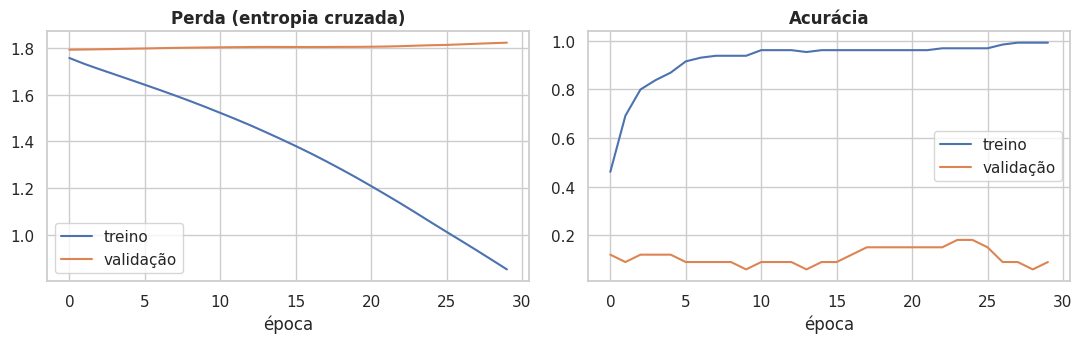

In [ ]:
def train_manual(Xtr, ytr, Xva=None, yva=None, hidden=None, activation="relu", l2=0.0, epochs=None, **kw):
    net = MLPManual(Xtr.shape[1], hidden or CFG["HIDDEN"], K, activation, l2, CFG["LR"])
    return net.fit(Xtr, ytr, Xva, yva, epochs=epochs or CFG["EPOCHS"], batch_size=CFG["BATCH"],
                   class_weight=CW, **kw)

t0 = time.time()
net_ref = train_manual(Xtr_t, y[idx_tr], Xval_t, y[idx_val], activation="relu", l2=CFG["L2"], record=True)
m_manual = compute_metrics(y[idx_val], net_ref.predict_proba(Xval_t))
print(f"MLP manual (ReLU, L2) — {time.time()-t0:.1f}s")
print(pd.Series(m_manual).round(4).to_string())

h = net_ref.history
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["train_loss"], label="treino"); ax[0].plot(h["val_loss"], label="validação")
ax[0].set(title="Perda (entropia cruzada)", xlabel="época"); ax[0].legend()
ax[1].plot(h["train_acc"], label="treino"); ax[1].plot(h["val_acc"], label="validação")
ax[1].set(title="Acurácia", xlabel="época"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"02_mlp_manual_curvas.png", dpi=150); plt.show()

## 3. Implementação equivalente em Keras/TensorFlow

Mesma arquitetura, mesmas inicializações (He/Glorot normal), mesma perda (entropia cruzada), mesmo otimizador (Adam, `lr`, `ε=1e-7`) e regularização L2 (`λ·ΣW²`, igual à da rede manual).
Se as duas implementações estiverem corretas, as curvas e métricas devem ser **muito próximas** (não idênticas: a ordem dos mini-lotes e as sementes de inicialização diferem).

Keras — 5.9s


,MLP manual,Keras,|Δ|
accuracy,0.0909,0.1212,0.0303
precision_macro,0.0333,0.1309,0.0976
recall_macro,0.1000,0.1333,0.0333
f1_micro,0.0909,0.1212,0.0303
f1_macro,0.0500,0.1229,0.0729
auroc_macro,0.4746,0.5000,0.0254


Concordância das previsões manual × Keras: 39.4%


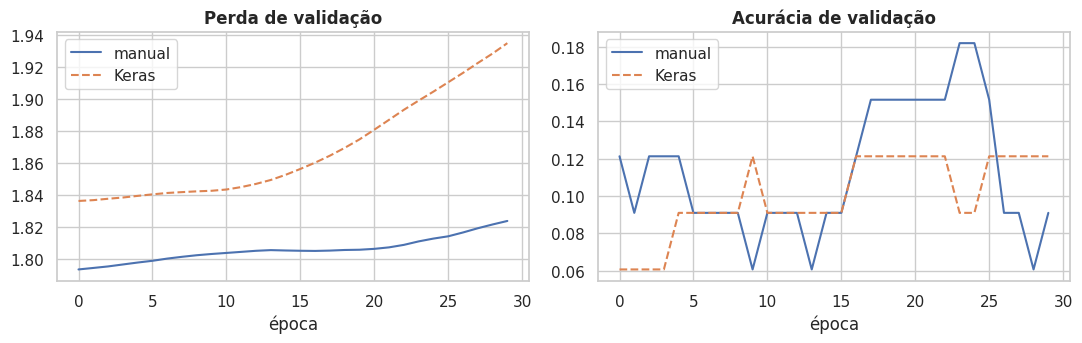

In [ ]:
def build_keras(n_in, hidden, n_out, activation="relu", l2=0.0, lr=1e-3):
    init = "he_normal" if activation == "relu" else "glorot_normal"
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    layers = [keras.Input((n_in,))]
    layers += [keras.layers.Dense(h, activation=activation, kernel_initializer=init, kernel_regularizer=reg) for h in hidden]
    layers += [keras.layers.Dense(n_out, activation="softmax", kernel_initializer="glorot_normal", kernel_regularizer=reg)]
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def fit_predict(kind, Xtr, ytr, Xte, hidden=None, activation="relu", l2=0.0, epochs=None,
                yte=None, record=False, seed=SEED):
    """Treina 'manual' ou 'keras' e devolve (probabilidades em Xte, histórico)."""
    hidden, epochs = hidden or CFG["HIDDEN"], epochs or CFG["EPOCHS"]
    if kind == "manual":
        net = MLPManual(Xtr.shape[1], hidden, K, activation, l2, CFG["LR"], seed)
        net.fit(Xtr, ytr, Xte if record else None, yte if record else None, epochs=epochs,
                batch_size=CFG["BATCH"], class_weight=CW, record=record, seed=seed)
        return net.predict_proba(Xte), net.history
    keras.utils.set_random_seed(seed)
    model = build_keras(Xtr.shape[1], hidden, K, activation, l2, CFG["LR"])
    val = (to_dense(Xte, np.float32), yte) if (record and yte is not None) else None
    hist = model.fit(to_dense(Xtr, np.float32), ytr, epochs=epochs, batch_size=CFG["BATCH"], verbose=0,
                     validation_data=val, class_weight=CW)
    proba = model.predict(to_dense(Xte, np.float32), verbose=0)
    keras.backend.clear_session()
    return proba, hist.history

t0 = time.time()
P_keras, h_keras = fit_predict("keras", Xtr_t, y[idx_tr], Xval_t, activation="relu", l2=CFG["L2"],
                               yte=y[idx_val], record=True)
m_keras = compute_metrics(y[idx_val], P_keras)
P_manual = net_ref.predict_proba(Xval_t)
print(f"Keras — {time.time()-t0:.1f}s")
cmp = pd.DataFrame({"MLP manual": m_manual, "Keras": m_keras}).round(4)
cmp["|Δ|"] = (cmp["MLP manual"] - cmp["Keras"]).abs().round(4)
display(cmp)
print(f"Concordância das previsões manual × Keras: {(P_manual.argmax(1) == P_keras.argmax(1)).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["val_loss"], label="manual"); ax[0].plot(h_keras["val_loss"], "--", label="Keras")
ax[0].set(title="Perda de validação", xlabel="época"); ax[0].legend()
ax[1].plot(h["val_acc"], label="manual"); ax[1].plot(h_keras["val_accuracy"], "--", label="Keras")
ax[1].set(title="Acurácia de validação", xlabel="época"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"03_manual_vs_keras.png", dpi=150); plt.show()

## 4. Busca de hiperparâmetros com 5-fold cross-validation

Grade completa (12 configurações), sempre sobre o conjunto `tv` (o teste não é usado aqui):

* **Ativação:** ReLU × Sigmoide
* **Regularização:** sem × L2 ($\lambda = 10^{-4}$)
* **Neurônios por camada:** (64, 32), (128, 64), (256, 128)

Para cada configuração, reportamos a **média** das 5 folds e o **IC de 95%** ($\bar x \pm t_{0.975,4}\,s/\sqrt5$). O critério de escolha é o **macro-F1** (adequado ao desbalanceamento).
Os folds (e o TF-IDF de cada fold, ajustado só no treino do fold) são os mesmos para todas as configurações, o que permite comparações pareadas.

In [ ]:
def prepare_folds(feat_fn, pool_idx, n_splits=5):
    """Pré-calcula (treino, validação, Xtr, Xva) de cada fold estratificado."""
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    out = []
    for a, b in skf.split(pool_idx, y[pool_idx]):
        tr, va = pool_idx[a], pool_idx[b]
        Xtr, Xva = feat_fn(tr, va)
        out.append((tr, va, Xtr, Xva))
    return out

def cv_run(kind, folds, hidden, activation, l2, epochs=None):
    rows = []
    for tr, va, Xtr, Xva in folds:
        proba, _ = fit_predict(kind, Xtr, y[tr], Xva, hidden, activation, l2, epochs)
        rows.append(compute_metrics(y[va], proba))
    return pd.DataFrame(rows)

def summarize(df_cv, metrics=("accuracy", "f1_macro", "auroc_macro")):
    s = {}
    for m_ in metrics:
        mu, lo, hi = mean_ci(df_cv[m_])
        s[f"{m_}_mean"], s[f"{m_}_lo"], s[f"{m_}_hi"] = mu, lo, hi
    return s

t0 = time.time()
folds_tfidf = prepare_folds(lambda tr, va: tfidf_features(texts[tr], texts[va])[:2], idx_tv)
print(f"TF-IDF por fold pronto em {time.time()-t0:.1f}s")

GRID = dict(activation=["relu", "sigmoid"], l2=[0.0, CFG["L2"]], hidden=[(64, 32), (128, 64), (256, 128)])
cv_folds, rows = {}, []
for act, l2, hid in itertools.product(GRID["activation"], GRID["l2"], GRID["hidden"]):
    t1 = time.time()
    d = cv_run("manual", folds_tfidf, hid, act, l2)
    cv_folds[(act, l2, hid)] = d
    rows.append(dict(ativacao=act, regularizacao="L2" if l2 > 0 else "sem", neuronios=f"{hid[0]}-{hid[1]}",
                     _key=(act, l2, hid), **summarize(d)))
    print(f"  {act:8s} {'L2 ' if l2 else 'sem'} {hid}  F1-macro={rows[-1]['f1_macro_mean']:.3f}  ({time.time()-t1:.0f}s)")

res = pd.DataFrame(rows).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)
fmt = lambda r, m_: f"{r[m_+'_mean']:.3f} [{r[m_+'_lo']:.3f}, {r[m_+'_hi']:.3f}]"
table_cv = pd.DataFrame({"ativação": res.ativacao, "regularização": res.regularizacao, "neurônios": res.neuronios,
                         "acurácia (média [IC95%])": res.apply(lambda r: fmt(r, "accuracy"), axis=1),
                         "macro-F1 (média [IC95%])": res.apply(lambda r: fmt(r, "f1_macro"), axis=1),
                         "AUROC (média [IC95%])": res.apply(lambda r: fmt(r, "auroc_macro"), axis=1)})
table_cv.to_csv(OUT / "tabela_cv_grid.csv", index=False)
display(table_cv)
BEST_KEY = res.loc[0, "_key"]
BEST = dict(activation=BEST_KEY[0], l2=BEST_KEY[1], hidden=BEST_KEY[2])
print("\nMelhor configuração (macro-F1 médio):", BEST)

TF-IDF por fold pronto em 0.3s
  relu     sem (64, 32)  F1-macro=0.157  (1s)
  relu     sem (128, 64)  F1-macro=0.185  (1s)
  relu     sem (256, 128)  F1-macro=0.207  (2s)
  relu     L2  (64, 32)  F1-macro=0.140  (1s)
  relu     L2  (128, 64)  F1-macro=0.199  (1s)
  relu     L2  (256, 128)  F1-macro=0.207  (2s)
  sigmoid  sem (64, 32)  F1-macro=0.053  (2s)
  sigmoid  sem (128, 64)  F1-macro=0.064  (2s)
  sigmoid  sem (256, 128)  F1-macro=0.065  (2s)
  sigmoid  L2  (64, 32)  F1-macro=0.053  (1s)
  sigmoid  L2  (128, 64)  F1-macro=0.065  (1s)
  sigmoid  L2  (256, 128)  F1-macro=0.053  (2s)


,ativação,regularização,neurônios,acurácia (média [IC95%]),macro-F1 (média [IC95%]),AUROC (média [IC95%])
0,relu,sem,256-128,"0.233 [0.152, 0.313]","0.207 [0.135, 0.279]","0.583 [0.514, 0.652]"
1,relu,L2,256-128,"0.233 [0.152, 0.313]","0.207 [0.136, 0.277]","0.585 [0.504, 0.666]"
2,relu,L2,128-64,"0.250 [0.104, 0.397]","0.199 [0.053, 0.344]","0.583 [0.518, 0.648]"
3,relu,sem,128-64,"0.232 [0.092, 0.372]","0.185 [0.045, 0.326]","0.587 [0.528, 0.646]"
4,relu,sem,64-32,"0.196 [0.088, 0.305]","0.157 [0.075, 0.239]","0.584 [0.543, 0.626]"
5,relu,L2,64-32,"0.184 [0.114, 0.255]","0.140 [0.102, 0.177]","0.579 [0.532, 0.626]"
6,sigmoid,L2,128-64,"0.196 [0.174, 0.218]","0.065 [0.039, 0.091]","0.581 [0.539, 0.623]"
7,sigmoid,sem,256-128,"0.196 [0.153, 0.240]","0.065 [0.029, 0.101]","0.603 [0.526, 0.680]"
8,sigmoid,sem,128-64,"0.196 [0.174, 0.218]","0.064 [0.041, 0.086]","0.582 [0.544, 0.621]"
9,sigmoid,sem,64-32,"0.190 [0.157, 0.224]","0.053 [0.045, 0.061]","0.582 [0.534, 0.631]"



Melhor configuração (macro-F1 médio): {'activation': 'relu', 'l2': 0.0, 'hidden': (256, 128)}


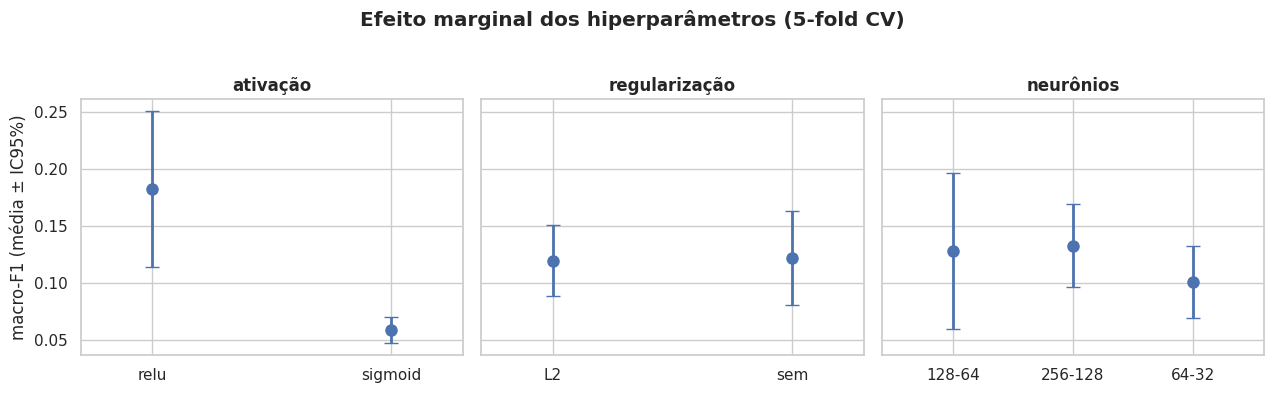

t pareado 1ª × 2ª melhor config: t=0.27, p=0.802  (indicativo; n=5 folds, folds não são independentes)


In [ ]:
# ---- efeito de cada hiperparâmetro (média das 5 folds × demais configurações) com IC 95%
long = []
for (act, l2, hid), d in cv_folds.items():
    for f, v in enumerate(d["f1_macro"]):
        long.append(dict(fold=f, **{"ativação": act, "regularização": "L2" if l2 else "sem", "neurônios": f"{hid[0]}-{hid[1]}"}, f1_macro=v))
long = pd.DataFrame(long)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a_, col in zip(ax, ["ativação", "regularização", "neurônios"]):
    # média por fold (sobre as demais configs) -> IC t sobre as 5 folds
    g = long.groupby([col, "fold"])["f1_macro"].mean().reset_index()
    stats_ = g.groupby(col)["f1_macro"].apply(lambda s: pd.Series(mean_ci(s), index=["m", "lo", "hi"])).unstack()
    a_.errorbar(range(len(stats_)), stats_["m"], yerr=[stats_["m"] - stats_["lo"], stats_["hi"] - stats_["m"]],
                fmt="o", capsize=5, lw=2, ms=8)
    a_.set_xticks(range(len(stats_))); a_.set_xticklabels(stats_.index); a_.set_title(col); a_.margins(x=0.3)
ax[0].set_ylabel("macro-F1 (média ± IC95%)")
fig.suptitle("Efeito marginal dos hiperparâmetros (5-fold CV)", y=1.03, fontweight="bold")
fig.tight_layout(); fig.savefig(OUT/"figs"/"04_efeito_hiperparametros.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- teste t pareado (mesmas folds) entre a 1ª e a 2ª melhores configurações
k1, k2 = res.loc[0, "_key"], res.loc[1, "_key"]
diff = cv_folds[k1]["f1_macro"].to_numpy() - cv_folds[k2]["f1_macro"].to_numpy()
if np.allclose(diff, 0):
    print("1ª e 2ª melhores configurações tiveram resultados idênticos nas 5 folds (teste t não se aplica).")
else:
    t_, p_ = stats.ttest_rel(cv_folds[k1]["f1_macro"], cv_folds[k2]["f1_macro"])
    print(f"t pareado 1ª × 2ª melhor config: t={t_:.2f}, p={p_:.3f}  (indicativo; n=5 folds, folds não são independentes)")

In [ ]:
# ---- validação cruzada da melhor configuração também no Keras (mesmos folds)
d_best_m = cv_folds[BEST_KEY]
d_best_k = cv_run("keras", folds_tfidf, BEST["hidden"], BEST["activation"], BEST["l2"])
rows = []
for nome, d in [("MLP manual", d_best_m), ("Keras", d_best_k)]:
    r = {"modelo": nome}
    for m_ in ["accuracy", "f1_macro", "auroc_macro"]:
        mu, lo, hi = mean_ci(d[m_]); r[m_] = f"{mu:.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(r)
cv_best_table = pd.DataFrame(rows); cv_best_table.to_csv(OUT / "tabela_cv_manual_vs_keras.csv", index=False)
display(cv_best_table)

,modelo,accuracy,f1_macro,auroc_macro
0,MLP manual,"0.233 [0.152, 0.313]","0.207 [0.135, 0.279]","0.583 [0.514, 0.652]"
1,Keras,"0.209 [0.097, 0.320]","0.203 [0.094, 0.313]","0.601 [0.540, 0.662]"


## 5. Diagnósticos, métricas e análise de pesos
### 5.1 Curvas de aprendizado: overfitting, underfitting, viés e variância

Duas visões para a melhor configuração: (a) perda/acurácia **por época** (treino × validação) e (b) macro-F1 em função do **tamanho do conjunto de treino**.
Heurística usada no diagnóstico automático (ajuste conforme o contexto do relatório):
*viés* ≈ $1-\text{F1}_\text{treino}$ (alto se > 0,20) e *variância* ≈ $\text{F1}_\text{treino}-\text{F1}_\text{val}$ (alta se > 0,10).

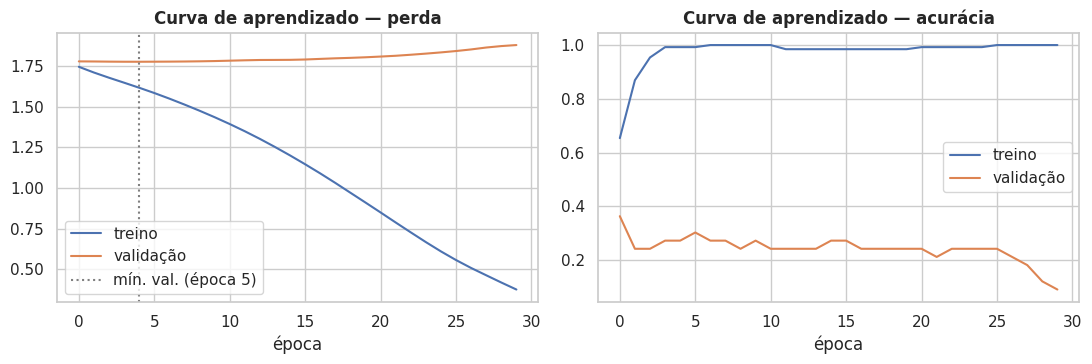

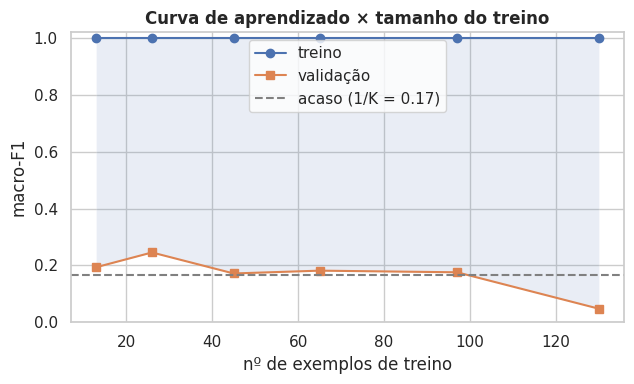

Viés (1 − F1 treino) = 0.000 | Variância (F1 treino − F1 val) = 0.952
Diagnóstico: ALTA VARIÂNCIA (overfitting) e viés baixo (o modelo ajusta bem o treino).
A curva de validação ainda sobe com mais dados -> mais dados ajudariam.


In [ ]:
net_best = train_manual(Xtr_t, y[idx_tr], Xval_t, y[idx_val], hidden=BEST["hidden"], activation=BEST["activation"],
                        l2=BEST["l2"], record=True)
hb = net_best.history
best_ep = int(np.argmin(hb["val_loss"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(hb["train_loss"], label="treino"); ax[0].plot(hb["val_loss"], label="validação")
ax[0].axvline(best_ep, color="gray", ls=":", label=f"mín. val. (época {best_ep+1})")
ax[0].set(title="Curva de aprendizado — perda", xlabel="época"); ax[0].legend()
ax[1].plot(hb["train_acc"], label="treino"); ax[1].plot(hb["val_acc"], label="validação")
ax[1].set(title="Curva de aprendizado — acurácia", xlabel="época"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"05a_curvas_epocas.png", dpi=150); plt.show()

# ---- curva por tamanho do conjunto de treino
fracs = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]
ytr_ = y[idx_tr]; lc = []
for f in fracs:
    sub = np.arange(len(idx_tr)) if f == 1 else train_test_split(np.arange(len(idx_tr)), train_size=f, stratify=ytr_, random_state=SEED)[0]
    net = train_manual(Xtr_t[sub], ytr_[sub], hidden=BEST["hidden"], activation=BEST["activation"], l2=BEST["l2"])
    lc.append(dict(n=len(sub),
                   f1_treino=f1_score(ytr_[sub], net.predict(Xtr_t[sub]), average="macro"),
                   f1_val=f1_score(y[idx_val], net.predict(Xval_t), average="macro")))
lc = pd.DataFrame(lc)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(lc.n, lc.f1_treino, "o-", label="treino"); ax.plot(lc.n, lc.f1_val, "s-", label="validação")
ax.axhline(1 / K, color="gray", ls="--", label=f"acaso (1/K = {1/K:.2f})")
ax.fill_between(lc.n, lc.f1_val, lc.f1_treino, alpha=0.12)
ax.set(title="Curva de aprendizado × tamanho do treino", xlabel="nº de exemplos de treino", ylabel="macro-F1", ylim=(0, 1.02)); ax.legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"05b_curva_tamanho_treino.png", dpi=150); plt.show()

f1_tr, f1_va = lc.f1_treino.iloc[-1], lc.f1_val.iloc[-1]
bias, var = 1 - f1_tr, f1_tr - f1_va
print(f"Viés (1 − F1 treino) = {bias:.3f} | Variância (F1 treino − F1 val) = {var:.3f}")
print("Diagnóstico:",
      ("ALTA VARIÂNCIA (overfitting) " if var > 0.10 else "variância moderada/baixa ") + "e " +
      ("ALTO VIÉS (underfitting)." if bias > 0.20 else "viés baixo (o modelo ajusta bem o treino)."))
print("Os dois lados da curva já convergiram?" if abs(lc.f1_val.iloc[-1] - lc.f1_val.iloc[-2]) < 0.01
      else "A curva de validação ainda sobe com mais dados -> mais dados ajudariam.")

### 5.2 Heatmaps da variação acumulada dos pesos e saturação (ReLU × Sigmoide)

Treinamos a mesma arquitetura com ReLU e com Sigmoide registrando, a cada época:

* a variação absoluta dos pesos que chegam a cada neurônio, $\sum_i |W_{ij}^{(\text{fim})}-W_{ij}^{(\text{início})}|$ — o heatmap mostra o **acúmulo** dessa variação ao longo das épocas (linhas = neurônios ordenados pelo total, colunas = épocas);
* a **saturação**: fração das ativações em regime saturado (sigmoide: $a<0{,}05$ ou $a>0{,}95$; ReLU: $a=0$) e fração de neurônios "mortos/travados" para toda a amostra monitorada;
* a **norma dos gradientes** por camada (indica *vanishing gradient*).

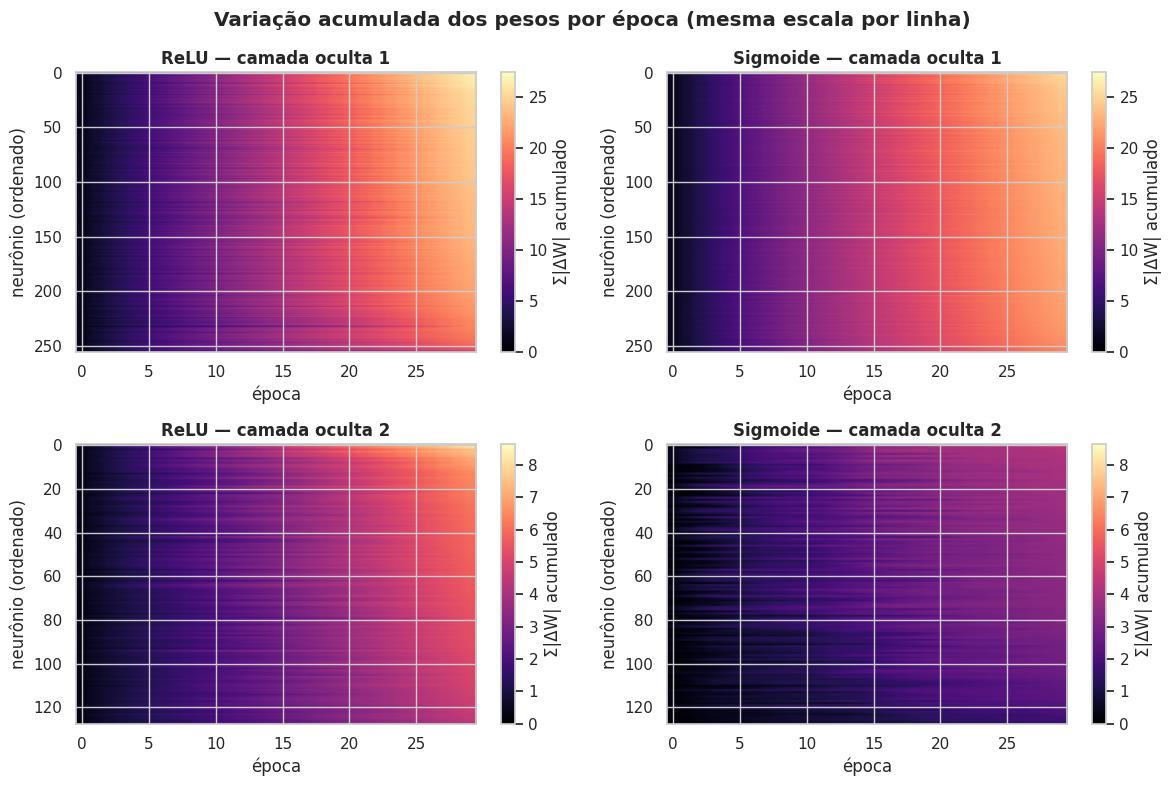

In [ ]:
nets_w = {act: train_manual(Xtr_t, y[idx_tr], hidden=BEST["hidden"], activation=act, l2=BEST["l2"], track=True)
          for act in ["relu", "sigmoid"]}
names = {"relu": "ReLU", "sigmoid": "Sigmoide"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r in range(2):                                              # r = camada oculta 1 ou 2
    mats = {}
    for act, net in nets_w.items():
        M = np.cumsum(np.array([ep[r] for ep in net.history["dW"]]), axis=0).T    # (neurônios × épocas)
        mats[act] = M[np.argsort(-M[:, -1])]
    vmax = max(m.max() for m in mats.values())
    for c, act in enumerate(["relu", "sigmoid"]):
        im = axes[r, c].imshow(mats[act], aspect="auto", cmap="magma", vmin=0, vmax=vmax)
        axes[r, c].set(title=f"{names[act]} — camada oculta {r+1}", xlabel="época", ylabel="neurônio (ordenado)")
        fig.colorbar(im, ax=axes[r, c], label="Σ|ΔW| acumulado")
fig.suptitle("Variação acumulada dos pesos por época (mesma escala por linha)", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT/"figs"/"05c_heatmaps_pesos.png", dpi=150); plt.show()

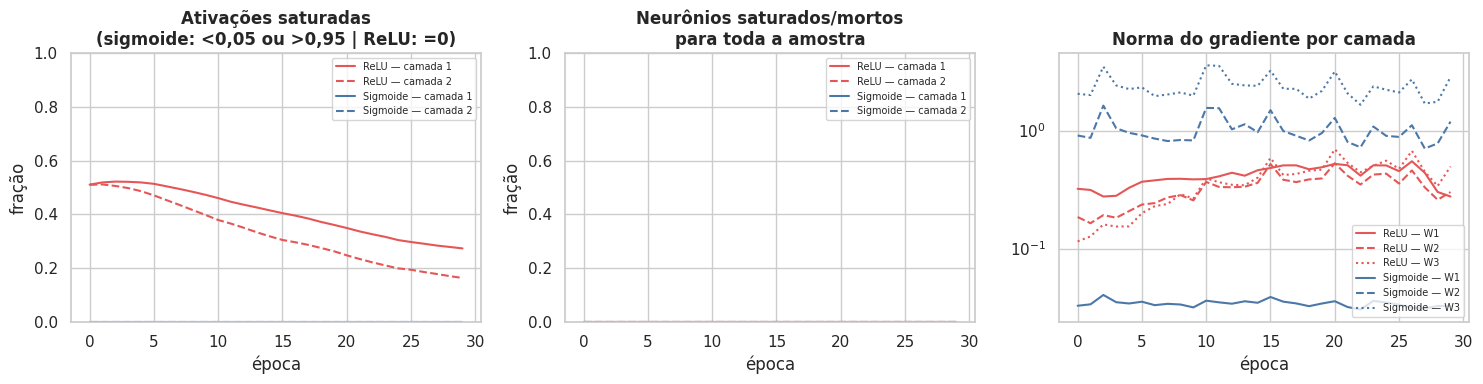

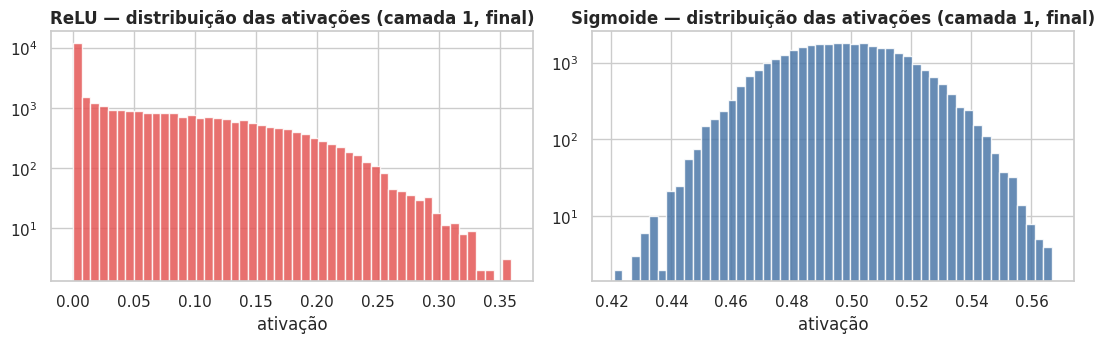

,ativação,saturação camada 1,saturação camada 2,neurônios travados c1,neurônios travados c2,‖∇W1‖ final,‖∇W3‖ final
0,ReLU,27.3%,16.3%,0.0%,0.0%,2.76e-01,4.95e-01
1,Sigmoide,0.0%,0.0%,0.0%,0.0%,3.27e-02,2.84e+00


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
col = {"relu": "#E45756", "sigmoid": "#4C78A8"}
for act, net in nets_w.items():
    hist_ = net.history
    sat, dead, gn = np.array(hist_["sat"]), np.array(hist_["dead"]), np.array(hist_["grad_norm"])
    for k, ls in zip(range(sat.shape[1]), ["-", "--"]):
        ax[0].plot(sat[:, k], ls=ls, color=col[act], label=f"{names[act]} — camada {k+1}")
        ax[1].plot(dead[:, k], ls=ls, color=col[act], label=f"{names[act]} — camada {k+1}")
    for k, ls in zip(range(gn.shape[1]), ["-", "--", ":"]):
        ax[2].plot(gn[:, k], ls=ls, color=col[act], label=f"{names[act]} — W{k+1}")
ax[0].set(title="Ativações saturadas\n(sigmoide: <0,05 ou >0,95 | ReLU: =0)", xlabel="época", ylabel="fração", ylim=(0, 1))
ax[1].set(title="Neurônios saturados/mortos\npara toda a amostra", xlabel="época", ylabel="fração", ylim=(0, 1))
ax[2].set(title="Norma do gradiente por camada", xlabel="época", yscale="log")
for a_ in ax: a_.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT/"figs"/"05d_saturacao.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a_, act in zip(ax, ["relu", "sigmoid"]):
    a_.hist(nets_w[act].monitor_acts[0].ravel(), bins=50, color=col[act], alpha=.85)
    a_.set(title=f"{names[act]} — distribuição das ativações (camada 1, final)", xlabel="ativação", yscale="log")
fig.tight_layout(); fig.savefig(OUT/"figs"/"05e_hist_ativacoes.png", dpi=150); plt.show()

summ = []
for act, net in nets_w.items():
    s_, d_ = net.history["sat"][-1], net.history["dead"][-1]
    summ.append({"ativação": names[act], "saturação camada 1": f"{s_[0]:.1%}", "saturação camada 2": f"{s_[1]:.1%}",
                 "neurônios travados c1": f"{d_[0]:.1%}", "neurônios travados c2": f"{d_[1]:.1%}",
                 "‖∇W1‖ final": f"{net.history['grad_norm'][-1][0]:.2e}", "‖∇W3‖ final": f"{net.history['grad_norm'][-1][-1]:.2e}"})
display(pd.DataFrame(summ))

### 5.3 Métricas no conjunto de teste: AUROC, precisão, revocação, micro-F1, macro-F1 × *Random Stratified Baseline*

Agora sim usamos o conjunto de teste: o TF-IDF é ajustado em `tv` (80%) e a melhor configuração é retreinada em `tv`.
O baseline *random stratified* sorteia a classe respeitando a distribuição do treino (média de 20 sementes); incluímos também o baseline da classe majoritária como referência.

In [ ]:
Xtv, Xte, vec_tv = tfidf_features(texts[idx_tv], texts[idx_test])
ytv, yte = y[idx_tv], y[idx_test]

P_m, _ = fit_predict("manual", Xtv, ytv, Xte, BEST["hidden"], BEST["activation"], BEST["l2"])
P_k, _ = fit_predict("keras",  Xtv, ytv, Xte, BEST["hidden"], BEST["activation"], BEST["l2"])

def baseline_metrics(strategy, seeds=range(20)):
    ms = []
    for s in seeds:
        dm = DummyClassifier(strategy=strategy, random_state=s).fit(np.zeros((len(ytv), 1)), ytv)
        ms.append(compute_metrics(yte, dm.predict_proba(np.zeros((len(yte), 1)))))
    return pd.DataFrame(ms).mean().to_dict()

tbl = pd.DataFrame({"MLP manual (TF-IDF, 2 camadas)": compute_metrics(yte, P_m),
                    "Keras (TF-IDF, 2 camadas)":      compute_metrics(yte, P_k),
                    "Random Stratified (baseline)":   baseline_metrics("stratified"),
                    "Classe majoritária (referência)": baseline_metrics("prior", [0])}).T
tbl.columns = ["acurácia", "precisão (macro)", "revocação (macro)", "micro-F1", "macro-F1", "AUROC (macro OvR)"]
display(tbl.round(4))
EN_COLS = ["accuracy", "precision_macro", "recall_macro", "f1_micro", "f1_macro", "auroc_macro"]
for nome in tbl.index:
    TEST_RESULTS.append(dict(modelo=nome, **dict(zip(EN_COLS, tbl.loc[nome].values))))
tbl.round(4).to_csv(OUT / "tabela_teste_tfidf.csv")

print("\nRelatório por classe (MLP manual):")
rep = pd.DataFrame(classification_report(yte, P_m.argmax(1), target_names=classes, output_dict=True, zero_division=0)).T
display(rep.round(3))

,acurácia,precisão (macro),revocação (macro),micro-F1,macro-F1,AUROC (macro OvR)
"MLP manual (TF-IDF, 2 camadas)",0.1951,0.1901,0.1875,0.1951,0.1764,0.5075
"Keras (TF-IDF, 2 camadas)",0.1463,0.2004,0.1528,0.1463,0.1670,0.5198
Random Stratified (baseline),0.1720,0.1686,0.1742,0.1720,0.1665,0.5042
Classe majoritária (referência),0.1951,0.0325,0.1667,0.1951,0.0544,0.5000



Relatório por classe (MLP manual):


,precision,recall,f1-score,support
science fiction fantasy': 3,0.357,0.625,0.455,8.000
science fiction (alternate history) ': 9,0.000,0.000,0.000,8.000
science fiction fantasy': 4,0.333,0.167,0.222,6.000
science fiction (alternate history) ': 12,0.200,0.167,0.182,6.000
science fiction (alternate history) ': 10,0.000,0.000,0.000,7.000
science fiction fantasy': 2},0.250,0.167,0.200,6.000
accuracy,0.195,0.195,0.195,0.195
macro avg,0.190,0.188,0.176,41.000
weighted avg,0.184,0.195,0.177,41.000


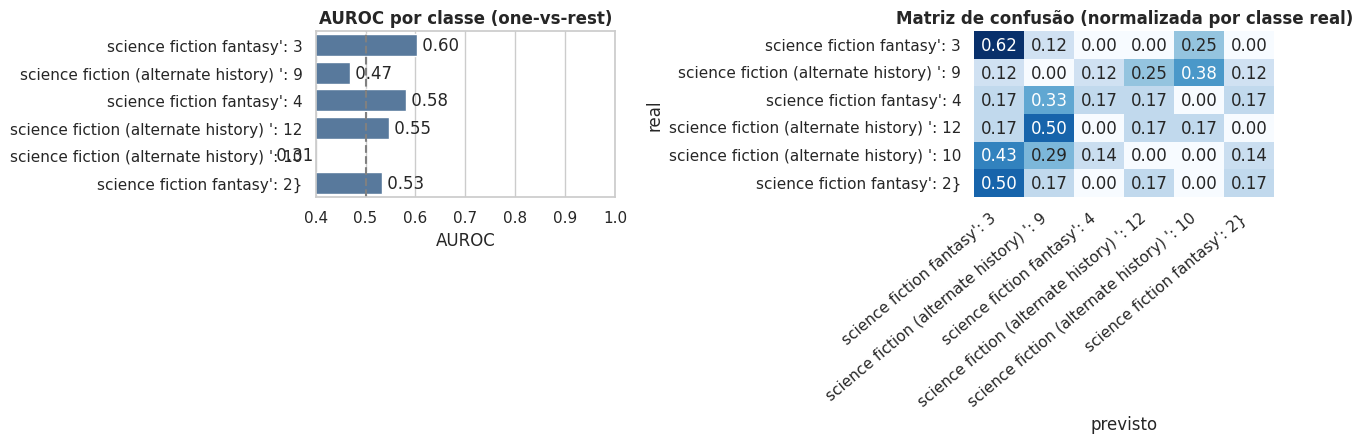

In [ ]:
# ---- AUROC por classe e matriz de confusão
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
aucs = [roc_auc_score((yte == k).astype(int), P_m[:, k]) for k in range(K)]
sns.barplot(x=aucs, y=classes, ax=ax[0], color="#4C78A8")
ax[0].axvline(0.5, color="gray", ls="--"); ax[0].set(title="AUROC por classe (one-vs-rest)", xlim=(0.4, 1.0), xlabel="AUROC")
for i, v in enumerate(aucs):
    ax[0].text(v, i, f" {v:.2f}", va="center")
cm = confusion_matrix(yte, P_m.argmax(1), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[1], cbar=False)
ax[1].set(title="Matriz de confusão (normalizada por classe real)", xlabel="previsto", ylabel="real")
plt.setp(ax[1].get_xticklabels(), rotation=40, ha="right")
fig.tight_layout(); fig.savefig(OUT/"figs"/"05f_auroc_confusao.png", dpi=150); plt.show()

## 6. Experimento com embeddings Skip-Gram

1. Treina-se um **Word2Vec Skip-Gram** (`sg=1`, janela 5, *negative sampling*) nas descrições do conjunto `tv` (o teste não participa; os rótulos também não são usados).
2. Cada descrição vira o **vetor concatenado** dos embeddings das suas primeiras `EMB_MAXLEN` palavras conhecidas (com *zero-padding*): entrada de dimensão `EMB_MAXLEN × EMB_DIM`, comparável à dimensão do TF-IDF.
3. A rede passa a ter **1 camada oculta** (dica da disciplina) e comparamos com o TF-IDF na mesma arquitetura (5-fold CV + teste).

Observação opcional: incluímos também a **média** dos embeddings (*mean-pooling*), que é invariante à posição das palavras, para contextualizar o resultado da concatenação (que depende da ordem).

Skip-Gram treinado em 2.6s | vocabulário: 2184 palavras | dim = 50
  world        -> survival, continent, came, horrifying, visionary
  history      -> vision, master, acclaimed, written, saga
  alternate    -> epic, saga, written, acclaimed, novels
  empire       -> roman, dark, tribune, fell, stands
Features concatenadas: (204, 2000) | média: (204, 50)


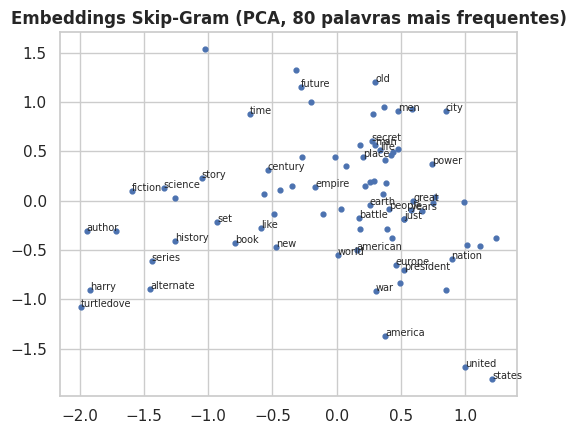

In [ ]:
t0 = time.time()
w2v = Word2Vec(sentences=[tokens[i] for i in idx_tv], vector_size=CFG["EMB_DIM"], window=5, min_count=2, sg=1,
               negative=10, epochs=CFG["W2V_EPOCHS"], workers=1, seed=SEED)
wv = w2v.wv
print(f"Skip-Gram treinado em {time.time()-t0:.1f}s | vocabulário: {len(wv)} palavras | dim = {CFG['EMB_DIM']}")

# sanidade: vizinhos de algumas palavras frequentes
freq_words = [w for w in wv.index_to_key[:60] if len(w) > 4][:4]
for w in freq_words:
    print(f"  {w:12s} ->", ", ".join(x for x, _ in wv.most_similar(w, topn=5)))

D, ML = CFG["EMB_DIM"], CFG["EMB_MAXLEN"]
def unit(v): return v / (np.linalg.norm(v) + 1e-9)

def embed_concat(idx):
    X = np.zeros((len(idx), ML * D), dtype=np.float32)
    for r, i in enumerate(idx):
        k = 0
        for t in tokens[i]:
            if t in wv.key_to_index:
                X[r, k * D:(k + 1) * D] = unit(wv[t]); k += 1
                if k == ML: break
    return X

def embed_mean(idx):
    X = np.zeros((len(idx), D), dtype=np.float32)
    for r, i in enumerate(idx):
        vs = [unit(wv[t]) for t in tokens[i] if t in wv.key_to_index]
        if vs: X[r] = np.mean(vs, axis=0)
    return X

E_concat, E_mean = embed_concat(idx_all), embed_mean(idx_all)
print("Features concatenadas:", E_concat.shape, "| média:", E_mean.shape)

fig, ax = plt.subplots(figsize=(5.5, 4.5))                                  # projeção 2-D (PCA) das palavras mais frequentes
from sklearn.decomposition import PCA
top = wv.index_to_key[:80]; P2 = PCA(2, random_state=SEED).fit_transform(np.array([wv[w] for w in top]))
ax.scatter(P2[:, 0], P2[:, 1], s=12)
for w, (a_, b_) in list(zip(top, P2))[:40]:
    ax.annotate(w, (a_, b_), fontsize=7)
ax.set_title("Embeddings Skip-Gram (PCA, 80 palavras mais frequentes)")
fig.tight_layout(); fig.savefig(OUT/"figs"/"06a_embeddings_pca.png", dpi=150); plt.show()

In [ ]:
H1 = (CFG["HIDDEN"][0],)                                   # 1 camada oculta
act, l2 = BEST["activation"], BEST["l2"]
print(f"Arquitetura com 1 camada oculta: {H1} | ativação={act} | L2={l2}")

folds_cat  = [(tr, va, E_concat[tr], E_concat[va]) for tr, va, _, _ in folds_tfidf]
folds_mean = [(tr, va, E_mean[tr],   E_mean[va])   for tr, va, _, _ in folds_tfidf]

cv_rows, cv_store = [], {}
for nome, folds in [("TF-IDF (1 camada)", folds_tfidf), ("Skip-Gram concatenado (1 camada)", folds_cat),
                    ("Skip-Gram média (1 camada) [extra]", folds_mean)]:
    t1 = time.time()
    d = cv_run("manual", folds, H1, act, l2); cv_store[nome] = d
    r = {"representação": nome}
    for m_ in ["accuracy", "f1_macro", "auroc_macro"]:
        mu, lo, hi = mean_ci(d[m_]); r[m_] = f"{mu:.3f} [{lo:.3f}, {hi:.3f}]"
    cv_rows.append(r); print(f"  {nome}: {time.time()-t1:.0f}s")
cv_emb = pd.DataFrame(cv_rows); cv_emb.to_csv(OUT / "tabela_cv_embeddings.csv", index=False)
display(cv_emb.rename(columns={"accuracy": "acurácia", "f1_macro": "macro-F1", "auroc_macro": "AUROC"}))

# referência: melhor MLP de 2 camadas com TF-IDF (CV)
mu, lo, hi = mean_ci(d_best_m["accuracy"]); print(f"Referência — TF-IDF, 2 camadas (melhor config): acurácia CV = {mu:.3f} [{lo:.3f}, {hi:.3f}]")
t_, p_ = stats.ttest_rel(cv_store["Skip-Gram concatenado (1 camada)"]["accuracy"], cv_store["TF-IDF (1 camada)"]["accuracy"])
print(f"t pareado acurácia Skip-Gram(concat) × TF-IDF: t={t_:.2f}, p={p_:.3f}")

Arquitetura com 1 camada oculta: (128,) | ativação=relu | L2=0.0
  TF-IDF (1 camada): 1s
  Skip-Gram concatenado (1 camada): 1s
  Skip-Gram média (1 camada) [extra]: 0s


,representação,acurácia,macro-F1,AUROC
0,TF-IDF (1 camada),"0.233 [0.173, 0.292]","0.165 [0.097, 0.233]","0.566 [0.515, 0.616]"
1,Skip-Gram concatenado (1 camada),"0.141 [0.078, 0.204]","0.089 [0.044, 0.133]","0.555 [0.523, 0.587]"
2,Skip-Gram média (1 camada) [extra],"0.184 [0.113, 0.256]","0.067 [0.034, 0.101]","0.554 [0.479, 0.629]"


Referência — TF-IDF, 2 camadas (melhor config): acurácia CV = 0.233 [0.152, 0.313]
t pareado acurácia Skip-Gram(concat) × TF-IDF: t=-3.40, p=0.027


,representação,implementação,accuracy,precision_macro,recall_macro,f1_micro,f1_macro,auroc_macro
0,TF-IDF (1 camada),MLP manual,0.1707,0.2628,0.1597,0.1707,0.1524,0.5548
1,TF-IDF (1 camada),Keras,0.1707,0.2775,0.1657,0.1707,0.1671,0.5446
2,Skip-Gram concatenado (1 camada),MLP manual,0.1951,0.3390,0.1974,0.1951,0.2096,0.4911
3,Skip-Gram concatenado (1 camada),Keras,0.1707,0.1423,0.1627,0.1707,0.1507,0.4582
4,Skip-Gram média (1 camada) [extra],MLP manual,0.1707,0.0565,0.1458,0.1707,0.0784,0.5750
5,Skip-Gram média (1 camada) [extra],Keras,0.1951,0.1227,0.2044,0.1951,0.1448,0.5905


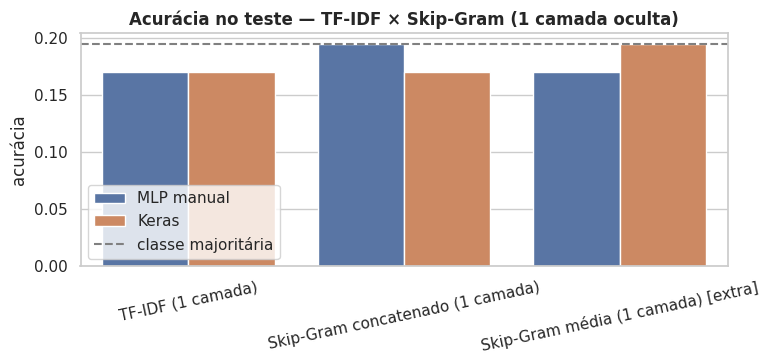

In [ ]:
# ---- avaliação no conjunto de teste (manual e Keras)
rows_emb = []
reps = {"TF-IDF (1 camada)": (Xtv, Xte),
        "Skip-Gram concatenado (1 camada)": (E_concat[idx_tv], E_concat[idx_test]),
        "Skip-Gram média (1 camada) [extra]": (E_mean[idx_tv], E_mean[idx_test])}
for nome, (A_, B_) in reps.items():
    for kind, kn in [("manual", "MLP manual"), ("keras", "Keras")]:
        P_, _ = fit_predict(kind, A_, ytv, B_, H1, act, l2)
        met = compute_metrics(yte, P_)
        rows_emb.append({"representação": nome, "implementação": kn, **met})
        TEST_RESULTS.append(dict(modelo=f"{kn} — {nome}", accuracy=met["accuracy"], precision_macro=met["precision_macro"],
                                 recall_macro=met["recall_macro"], f1_micro=met["f1_micro"], f1_macro=met["f1_macro"],
                                 auroc_macro=met["auroc_macro"]))
emb_test = pd.DataFrame(rows_emb)
emb_test.round(4).to_csv(OUT / "tabela_teste_embeddings.csv", index=False)
display(emb_test.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=emb_test, x="representação", y="accuracy", hue="implementação", ax=ax)
ax.axhline(tbl.loc["Classe majoritária (referência)", "acurácia"], color="gray", ls="--", label="classe majoritária")
ax.set(title="Acurácia no teste — TF-IDF × Skip-Gram (1 camada oculta)", xlabel="", ylabel="acurácia"); ax.legend()
plt.setp(ax.get_xticklabels(), rotation=12); fig.tight_layout()
fig.savefig(OUT/"figs"/"06b_embeddings_vs_tfidf.png", dpi=150); plt.show()

## 7. Resumo dos resultados e conclusão

,acurácia,precisão (macro),revocação (macro),micro-F1,macro-F1,AUROC (macro)
modelo,,,,,,
MLP manual — Skip-Gram concatenado (1 camada),0.1951,0.3390,0.1974,0.1951,0.2096,0.4911
"MLP manual (TF-IDF, 2 camadas)",0.1951,0.1901,0.1875,0.1951,0.1764,0.5075
Keras — TF-IDF (1 camada),0.1707,0.2775,0.1657,0.1707,0.1671,0.5446
"Keras (TF-IDF, 2 camadas)",0.1463,0.2004,0.1528,0.1463,0.1670,0.5198
Random Stratified (baseline),0.1720,0.1686,0.1742,0.1720,0.1665,0.5042
MLP manual — TF-IDF (1 camada),0.1707,0.2628,0.1597,0.1707,0.1524,0.5548
Keras — Skip-Gram concatenado (1 camada),0.1707,0.1423,0.1627,0.1707,0.1507,0.4582
Keras — Skip-Gram média (1 camada) [extra],0.1951,0.1227,0.2044,0.1951,0.1448,0.5905
MLP manual — Skip-Gram média (1 camada) [extra],0.1707,0.0565,0.1458,0.1707,0.0784,0.5750


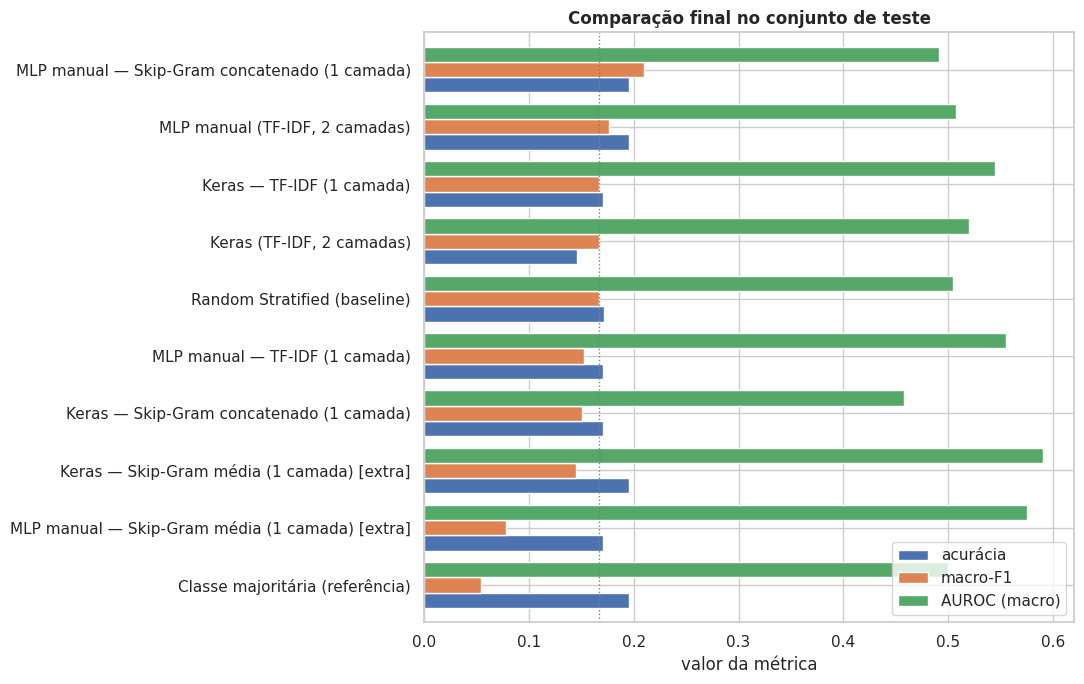


RESUMO AUTOMÁTICO (use como ponto de partida para o texto do relatório)
- Problema: 6 subgêneros (science fiction fantasy': 3, science fiction (alternate history) ': 9, science fiction fantasy': 4, science fiction (alternate history) ': 12, science fiction (alternate history) ': 10, science fiction fantasy': 2}); razão de desbalanceamento 1.4x; 204 livros.
- Melhor configuração (5-fold, macro-F1): ativação=relu, L2=não, neurônios=(256, 128).
- Teste: macro-F1 = 0.176 (baseline estratificado = 0.166); AUROC = 0.507 (baseline = 0.504).
- Rede manual × Keras: diferença de macro-F1 de 0.009 -> implementações consistentes.
- Skip-Gram (concat., 1 camada) acurácia = 0.195 vs TF-IDF (1 camada) = 0.171.



In [ ]:
final = pd.DataFrame(TEST_RESULTS).drop_duplicates("modelo", keep="last").set_index("modelo")
final.columns = ["acurácia", "precisão (macro)", "revocação (macro)", "micro-F1", "macro-F1", "AUROC (macro)"]
final = final.sort_values("macro-F1", ascending=False)
final.round(4).to_csv(OUT / "resumo_final_teste.csv")
display(final.round(4))

fig, ax = plt.subplots(figsize=(11, 0.55 * len(final) + 1.5))
final[["acurácia", "macro-F1", "AUROC (macro)"]].iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.axvline(1 / K, color="gray", ls=":", lw=1)
ax.set(title="Comparação final no conjunto de teste", xlabel="valor da métrica", ylabel=""); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(OUT/"figs"/"07_resumo_final.png", dpi=150); plt.show()

# ---- resumo textual com os números reais desta execução
b = final.loc[[i for i in final.index if "TF-IDF, 2 camadas" in i and "manual" in i.lower()][0]]
base = final.loc["Random Stratified (baseline)"]
is_man = emb_test["implementação"] == "MLP manual"
emb_c = emb_test[is_man & emb_test["representação"].str.contains("concatenado")].iloc[0]
tf1 = emb_test[is_man & (emb_test["representação"] == "TF-IDF (1 camada)")].iloc[0]
print(f"""
RESUMO AUTOMÁTICO (use como ponto de partida para o texto do relatório)
- Problema: {K} subgêneros ({', '.join(classes)}); razão de desbalanceamento {dist.max()/dist.min():.1f}x; {len(df)} livros.
- Melhor configuração (5-fold, macro-F1): ativação={BEST['activation']}, L2={'sim' if BEST['l2']>0 else 'não'}, neurônios={BEST['hidden']}.
- Teste: macro-F1 = {b['macro-F1']:.3f} (baseline estratificado = {base['macro-F1']:.3f}); AUROC = {b['AUROC (macro)']:.3f} (baseline = {base['AUROC (macro)']:.3f}).
- Rede manual × Keras: diferença de macro-F1 de {abs(tbl.iloc[0]['macro-F1']-tbl.iloc[1]['macro-F1']):.3f} -> implementações consistentes.
- Skip-Gram (concat., 1 camada) acurácia = {emb_c['accuracy']:.3f} vs TF-IDF (1 camada) = {tf1['accuracy']:.3f}.
""")

### Roteiro sugerido para a conclusão do relatório / apresentação (15 min)

1. **Problema e dados (2 min):** dataset, subgêneros escolhidos, desbalanceamento (gráfico 01), limpeza e TF-IDF.
2. **Implementação (3 min):** MLP manual (equações do forward/backprop, *gradient check*) e validação contra o Keras (figura 03).
3. **Hiperparâmetros (3 min):** tabela do 5-fold com IC 95% e efeito marginal de ativação, L2 e nº de neurônios (figuras 04).
4. **Diagnósticos (3 min):** curvas de aprendizado → viés × variância (05a/05b); heatmaps e saturação ReLU × Sigmoide (05c–05e).
5. **Métricas e embeddings (3 min):** AUROC/P/R/F1 × baseline (05f, tabela) e Skip-Gram × TF-IDF com 1 camada (06b).
6. **Conclusões (1 min):** o que funcionou, limitações (rótulos ruidosos/sobrepostos, descrições curtas, ordem das palavras na concatenação) e próximos passos (class weights, early stopping, CNN/LSTM, embeddings pré-treinados).

**Pontos para discutir no texto:** (i) por que o macro-F1 é menor que a acurácia em dados desbalanceados; (ii) se os ICs das configurações se sobrepõem (então a escolha não é estatisticamente forte); (iii) por que a sigmoide satura/atenua gradientes e a ReLU pode ter neurônios mortos; (iv) por que a concatenação de embeddings tende a perder para o TF-IDF (dependência de posição e truncamento) — e o que a média dos embeddings mostra.